# 06 – Checks requested by the review

**B. Dropped rows (selection bias).** An observation is only used if the player has a valuation 12 months later (± 60 days). Who is dropped, and could this bias the results?

**C. Forecast intervals.** Quantile LightGBM models give an 80% interval for each forecast.

**D. Checks on weak spots.** New-league feature gaps, snapshot features, and real transfer fees.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.config import (RESULTS, SEED, TRAIN_END, VAL_END, HORIZON_DAYS, HORIZON_TOL_DAYS, set_seed, savefig,
                        apply_plot_style, PALETTE, TEXT_SECONDARY, GRID, VALUE_BINS, VALUE_LABELS, AGE_BINS, AGE_LABELS)
from src.features import load_tables, build_features, add_target
from src.analysis import cluster_bootstrap_means, ci

import numpy as np, pandas as pd, matplotlib.pyplot as plt

set_seed(SEED)
apply_plot_style()
pd.set_option("display.width", 170, "display.max_columns", 30)
DAY = pd.Timedelta(days=1)

## B1. How many observations are dropped?

We rebuild the features and the target for **every** valuation from July 2014 on (as in notebook 02). An observation without a valuation in $[t+305, t+425]$ days is dropped. There are two very different reasons:
- **Censored by the end of the data:** the window $t+425$ days lies after the last valuation in the data. The target simply cannot exist yet. This affects every observation from mid-April 2025 on, whatever happens to the player.
- **Genuine drop:** the window lies completely inside the data, but the player has no valuation in it. Only these drops can bias the results.

In [2]:
d = load_tables()
F = add_target(build_features(d, verbose=False), d["vals"])
F = F[F["t"] >= "2014-07-01"].reset_index(drop=True)
END = d["vals"]["date"].max()
cov = pd.read_csv(RESULTS / "table03_league_coverage.csv")
CORE = set(cov.loc[cov.group == "core", "competition_id"]); NEW = set(cov.loc[cov.group == "new_leagues", "competition_id"])
lg = F["league_t"].astype(str)
F["league_group"] = np.select([lg.isin(CORE), lg.isin(NEW)], ["core", "new_leagues"], default=lg)
F["period"] = np.select([F.t < TRAIN_END, F.t < VAL_END], ["train", "val"], default="test")
F["kept"] = F["y"].notna()
F["complete_window"] = (F["t"] + (HORIZON_DAYS + HORIZON_TOL_DAYS) * DAY) <= END
F["status"] = np.select([F.kept & F.complete_window, F.kept, F.complete_window],
                        ["kept", "kept (window partly after data end)", "dropped: no valuation in window"],
                        default="dropped: window after data end")
print(f"last valuation in the data: {END.date()} | last t with a complete window: {(END - 425 * DAY).date()}")

def counts(frame):
    order = ["kept", "kept (window partly after data end)", "dropped: no valuation in window",
             "dropped: window after data end"]
    t = (frame.groupby(["period", "status"]).size().unstack(fill_value=0)
              .reindex(index=["train", "val", "test"], columns=order, fill_value=0))
    t["total"] = t.sum(axis=1)
    t.loc["all periods"] = t.sum()
    t["genuine drop rate (% of complete-window rows)"] = (100 * t["dropped: no valuation in window"] /
        (t["kept"] + t["dropped: no valuation in window"])).round(1)
    return t

drop_all, drop_core = counts(F), counts(F[F.league_group == "core"])
pd.concat({"all leagues": drop_all, "14 core leagues": drop_core}).to_csv(RESULTS / "table27_dropped_rows_counts.csv")
print("All leagues:"); display(drop_all)
print("14 core leagues (main experiments):"); display(drop_core)

last valuation in the data: 2026-06-12 | last t with a complete window: 2025-04-13
All leagues:


status,kept,kept (window partly after data end),dropped: no valuation in window,dropped: window after data end,total,genuine drop rate (% of complete-window rows)
period,,,,,,
train,285378,0,111675,0,397053,28.1
val,36376,0,15246,0,51622,29.5
test,20688,15288,4907,46600,87483,19.2
all periods,342442,15288,131828,46600,536158,27.8


14 core leagues (main experiments):


status,kept,kept (window partly after data end),dropped: no valuation in window,dropped: window after data end,total,genuine drop rate (% of complete-window rows)
period,,,,,,
train,112782,0,31176,0,143958,21.7
val,11711,0,6417,0,18128,35.4
test,7409,4758,2530,17953,32650,25.5
all periods,131902,4758,40123,17953,194736,23.3


**Note on the test period.** Test observations from mid-April to mid-August 2025 have only a *partly* observable window. They are kept only if the next valuation came early enough (by June 2026). This is a mild timing effect, and it is separate from the genuine drops studied below.

## B2. Who is dropped? (genuine drops only)

We compare genuine drops with kept observations, using only observations whose window is complete.
- **Drop rate** = genuine drops / (kept + genuine drops), per group.
- **"Any later valuation?"** asks whether the player ever receives another valuation after $t$. If not, the player most likely retired or stopped being tracked (for example after moving to a league Transfermarkt covers less).

In [3]:
vals = d["vals"][d["vals"]["market_value_in_eur"] > 0][["player_id", "date", "market_value_in_eur"]]
last_val = vals.groupby("player_id")["date"].max()
C_ = F[F.complete_window].copy()
C_["any later valuation"] = np.where(C_["t"] < C_["player_id"].map(last_val), "yes", "no (retired / no longer tracked)")
C_["age group"] = pd.cut(C_["age"], AGE_BINS, labels=AGE_LABELS, right=False)
C_["value level"] = pd.cut(C_["value_t"], VALUE_BINS, labels=VALUE_LABELS, right=False)
C_["dropped"] = (~C_["kept"]).astype(float)

def breakdown(frame, var):
    g = frame.groupby(var, observed=True)
    return pd.DataFrame({"rows": g.size(), "genuine drops": g["dropped"].sum().astype(int),
                         "drop rate %": (100 * g["dropped"].mean()).round(1)})

def all_breakdowns(frame):
    parts = {v: breakdown(frame, v) for v in ["age group", "value level", "league_group", "any later valuation"]}
    out = pd.concat(parts, names=["grouping", "group"])
    out.loc[("all", "all"), :] = [len(frame), int(frame["dropped"].sum()), round(100 * frame["dropped"].mean(), 1)]
    return out

bd_test_core = all_breakdowns(C_[(C_.period == "test") & (C_.league_group == "core")])
bd_all = all_breakdowns(C_)
by_league = breakdown(C_[C_.league_group == "core"], "league_t").sort_values("drop rate %")
pd.concat({"test period, core leagues": bd_test_core, "all periods, all leagues": bd_all}).to_csv(
    RESULTS / "table28_dropped_rows_breakdown.csv")
by_league.to_csv(RESULTS / "table28b_dropped_rows_by_core_league.csv")
print("Test period, 14 core leagues (complete windows only):"); display(bd_test_core)
print("All periods, all leagues:"); display(bd_all)
print("Drop rate by core league (all periods):"); display(by_league.T)

Test period, 14 core leagues (complete windows only):


rows  genuine drops  drop rate %
grouping            group                                                               
age group           <21                               1590.0          480.0         30.2
                    21–25                             4071.0          966.0         23.7
                    26–29                             2532.0          633.0         25.0
                    30+                               1745.0          450.0         25.8
value level         cheap (<€1m)                      3717.0         1046.0         28.1
                    medium (€1–10m)                   4313.0         1029.0         23.9
                    expensive (≥€10m)                 1909.0          455.0         23.8
league_group        core                              9939.0         2530.0         25.5
any later valuation no (retired / no longer tracked)    32.0           32.0        100.0
                    yes                               9907.0         2498.0         25.2
all                 all                               9939.0         2530.0         25.5

All periods, all leagues:


rows  genuine drops  drop rate %
grouping            group                                                                 
age group           <21                                88744.0        24648.0         27.8
                    21–25                             186264.0        46337.0         24.9
                    26–29                             113148.0        29707.0         26.3
                    30+                                85834.0        31033.0         36.2
value level         cheap (<€1m)                      326775.0       102959.0         31.5
                    medium (€1–10m)                   122711.0        24760.0         20.2
                    expensive (≥€10m)                  24784.0         4109.0         16.6
league_group        OTHER                             166713.0        35333.0         21.2
                    UNKNOWN                           131856.0        55746.0         42.3
                    core                              172025.0        40123.0         23.3
                    new_leagues                         3676.0          626.0         17.0
any later valuation no (retired / no longer tracked)   21103.0        21103.0        100.0
                    yes                               453167.0       110725.0         24.4
all                 all                               474270.0       131828.0         27.8

Drop rate by core league (all periods):


league_t,L1,RU1,DK1,IT1,FR1,ES1,GB1,TR1,NL1,PO1,UKR1,BE1,SC1,GR1
rows,13878.0,10935.0,8021.0,15382.0,14219.0,15395.0,14543.0,17179.0,12983.0,12993.0,8372.0,12059.0,6247.0,9819.0
genuine drops,2093.0,1764.0,1351.0,2679.0,3057.0,3495.0,3314.0,4439.0,3402.0,3429.0,2307.0,3486.0,1943.0,3364.0
drop rate %,15.1,16.1,16.8,17.4,21.5,22.7,22.8,25.8,26.2,26.4,27.6,28.9,31.1,34.3


In [4]:
# what share of genuine drops never get another valuation?
gd = C_[C_["dropped"] == 1]
share_none = (gd["any later valuation"] != "yes").mean()
print(f"Genuine drops with NO later valuation at all: {100 * share_none:.1f}% (all periods, all leagues)")
gd_tc = gd[(gd.period == "test") & (gd.league_group == "core")]
print(f"  ... in the test period, core leagues: {100 * (gd_tc['any later valuation'] != 'yes').mean():.1f}% of {len(gd_tc):,}")

Genuine drops with NO later valuation at all: 16.0% (all periods, all leagues)
  ... in the test period, core leagues: 1.3% of 2,530


## B3. Dropped observations that do get a later valuation: what happened to them?

For genuine drops that have a valuation within **18 months** after $t$, we take the valuation closest to $t+365$ days in $(t, t+548]$ and compute the log change.

We compare these changes with those of kept observations: are drops mostly falls? Note that the comparison is not like-for-like:
- these later valuations come either **before** 10 months or **after** 14 months;
- so the time span differs from the kept observations' 12 months, and the gap is reported alongside.

In [5]:
later = vals.rename(columns={"date": "later_date", "market_value_in_eur": "later_value"}).sort_values("later_date")
q = C_[["player_id", "t", "log_value", "kept", "period", "league_group", "age group"]].copy()
q["q"] = q["t"] + HORIZON_DAYS * DAY
q = q.sort_values("q")
m = pd.merge_asof(q, later, left_on="q", right_on="later_date", by="player_id", direction="nearest",
                  tolerance=365 * DAY)
m = m[(m["later_date"] > m["t"]) & (m["later_date"] <= m["t"] + 548 * DAY)]
m["change"] = np.log(m["later_value"].astype(float)) - m["log_value"]
m["gap_days"] = (m["later_date"] - m["t"]).dt.days

def describe(frame):
    c = frame["change"]
    return pd.Series({"rows": len(frame), "median gap (days)": frame["gap_days"].median(),
                      "median log change": c.median(), "rose %": 100 * (c > 0).mean(),
                      "unchanged %": 100 * (c == 0).mean(), "fell %": 100 * (c < 0).mean(),
                      "fell >33% (%)": 100 * (c < np.log(0.67)).mean()})

gd_m = m[~m["kept"]]
rows = {
    "kept (12-month target), all": describe(m[m["kept"]]),
    "genuine drops with a later valuation ≤18m, all": describe(gd_m),
    "  … later valuation before 10 months": describe(gd_m[gd_m.gap_days < 305]),
    "  … later valuation after 14 months": describe(gd_m[gd_m.gap_days > 425]),
    "kept, test period, core": describe(m[m["kept"] & (m.period == "test") & (m.league_group == "core")]),
    "genuine drops ≤18m, test period, core": describe(gd_m[(gd_m.period == "test") & (gd_m.league_group == "core")]),
}
later_tab = pd.DataFrame(rows).T.round(2)
later_tab["rows"] = later_tab["rows"].astype(int)
later_tab.to_csv(RESULTS / "table29_dropped_rows_later_change.csv")
n_gd = (~C_["kept"]).sum()
print(f"genuine drops with a valuation within 18 months: {len(gd_m):,} of {n_gd:,} ({100 * len(gd_m) / n_gd:.1f}%)")
later_tab

genuine drops with a valuation within 18 months: 103,753 of 131,828 (78.7%)


,rows,median gap (days),median log change,rose %,unchanged %,fell %,fell >33% (%)
"kept (12-month target), all",342442,364.0,0.00,42.16,16.91,40.93,19.88
"genuine drops with a later valuation ≤18m, all",103753,298.0,0.00,34.22,22.60,43.19,20.83
… later valuation before 10 months,59203,250.0,0.00,27.83,27.80,44.36,19.63
… later valuation after 14 months,44550,444.0,0.00,42.70,15.68,41.62,22.43
"kept, test period, core",7409,364.0,-0.06,37.08,12.57,50.36,26.89
"genuine drops ≤18m, test period, core",2497,432.0,0.00,33.48,16.90,49.62,26.39


In [6]:
by_age = (pd.concat({"kept": m[m.kept], "dropped": gd_m})
            .reset_index(level=0).rename(columns={"level_0": "status"})
            .groupby(["age group", "status"], observed=True)["change"]
            .agg(rows="size", median="median", fell_pct=lambda c: 100 * (c < 0).mean()).round(3).unstack())
by_age.to_csv(RESULTS / "table29b_dropped_rows_later_change_by_age.csv")
by_age

rows          median        fell_pct        
status    dropped    kept dropped   kept  dropped    kept
age group                                                
<21         20202   64096   0.208  0.405   17.127  17.489
21–25       38074  139927   0.000  0.074   35.111  33.009
26–29       24015   83441  -0.095 -0.061   52.659  50.444
30+         21394   54801  -0.288 -0.310   71.469  74.002

## B5. Why is the drop rate higher in the validation season (2023/24)?

Transfermarkt updates values in **rounds**:
- **Main rounds** (around June and December) cover most players of a league.
- **Smaller in-between rounds** (e.g. March, September/October, May) cover only some players, and their month changes from year to year.

A valuation from an in-between round often has no valuation 10–14 months later, so the observation is dropped. Below we check this by season (core leagues, complete windows only).

In [7]:
c = C_[C_.league_group == "core"].copy()
c["season"] = np.where(c.t.dt.month >= 7, c.t.dt.year, c.t.dt.year - 1)
c["round"] = np.where(c.t.dt.month.isin([5, 6, 11, 12]), "main round (May/Jun, Nov/Dec)", "in-between round")
by_season = c.groupby(["season", "round"]).agg(rows=("dropped", "size"), drop_rate=("dropped", "mean")).unstack()
by_season.columns = [f"{a} – {b}" for a, b in by_season.columns]
by_season["share in-between %"] = 100 * by_season["rows – in-between round"] / (
    by_season["rows – in-between round"] + by_season["rows – main round (May/Jun, Nov/Dec)"])
by_season["drop rate all %"] = 100 * c.groupby("season")["dropped"].mean()
for col in [k for k in by_season.columns if k.startswith("drop_rate")]:
    by_season[col] = 100 * by_season[col]
by_season = by_season.round(1)
by_season.to_csv(RESULTS / "table30_drop_rate_by_season_and_round.csv")
display(by_season)

# decomposition for 2023/24 vs the average of 2018/19-2022/23: mix of rounds vs drop rate within rounds
ref = c[c.season.between(2018, 2022)]
val = c[c.season == 2023]
r_ref = ref.groupby("round")["dropped"].mean(); w_ref = ref["round"].value_counts(normalize=True)
r_val = val.groupby("round")["dropped"].mean(); w_val = val["round"].value_counts(normalize=True)
mix = 100 * ((w_val - w_ref) * r_ref).sum()
within = 100 * (w_val * (r_val - r_ref)).sum()
print(f"2023/24 drop rate {100 * val.dropped.mean():.1f}% vs {100 * ref.dropped.mean():.1f}% in 2018/19–2022/23 "
      f"(+{100 * (val.dropped.mean() - ref.dropped.mean()):.1f} points): "
      f"{mix:+.1f} from more in-between-round valuations, {within:+.1f} from higher drop rates within rounds")

excess = (val.groupby("league_t")["dropped"].sum() - val.groupby("league_t").size() * ref.groupby("league_t")["dropped"].mean())
excess = excess.sort_values(ascending=False).round(0)
excess.to_csv(RESULTS / "table30b_excess_drops_2023_by_league.csv")
print("excess drops in 2023/24 by league (vs own 2018–22 rate):", excess.to_dict())

# how many valuations Transfermarkt recorded per calendar year (all players in the data)
per_year = vals.groupby(vals["date"].dt.year).size().loc[2019:2025]
per_year.rename("valuations recorded").to_frame().T.to_csv(RESULTS / "table30c_valuations_per_year.csv")
print("valuations recorded per year:", per_year.to_dict())
print(f"2024 vs 2023: {100 * (per_year[2024] / per_year[2023] - 1):+.1f}%  (the 2023/24 targets fall in mid-2024 to mid-2025)")

,rows – in-between round,"rows – main round (May/Jun, Nov/Dec)",drop_rate – in-between round,"drop_rate – main round (May/Jun, Nov/Dec)",share in-between %,drop rate all %
season,,,,,,
2014,10371,3691,16.9,25.6,73.8,19.2
2015,10178,2501,20.7,32.0,80.3,23.0
2016,11169,7448,16.7,13.8,60.0,15.5
2017,5952,8043,27.9,9.9,42.5,17.5
2018,4447,10910,24.7,28.3,29.0,27.2
2019,9237,5316,18.9,17.6,63.5,18.4
2020,12021,9108,43.9,6.3,56.9,27.7
2021,5800,10532,39.6,6.4,35.5,18.2
2022,4329,12905,56.2,16.3,25.1,26.3


2023/24 drop rate 35.4% vs 23.9% in 2018/19–2022/23 (+11.5 points): -3.3 from more in-between-round valuations, +14.8 from higher drop rates within rounds
excess drops in 2023/24 by league (vs own 2018–22 rate): {'TR1': 530.0, 'L1': 245.0, 'RU1': 244.0, 'ES1': 210.0, 'PO1': 184.0, 'GR1': 183.0, 'IT1': 182.0, 'SC1': 106.0, 'FR1': 72.0, 'DK1': 70.0, 'UKR1': 46.0, 'NL1': 14.0, 'BE1': -13.0, 'GB1': -25.0}
valuations recorded per year: {2019: 46088, 2020: 48749, 2021: 58412, 2022: 59564, 2023: 57576, 2024: 45376, 2025: 45482}
2024 vs 2023: -21.2%  (the 2023/24 targets fall in mid-2024 to mid-2025)


## B6. Sensitivity: test results on observations with a fully observable window only

Test observations from mid-April 2025 on are kept only if their next valuation came early (before the data end in June 2026). Here we re-score the main comparison using only test observations with $t + 425$ days $\le$ the last date in the data. Their whole 10–14-month window is observable, so they were not kept because of early updates.

In [8]:
import json
from src.analysis import verdict
preds = pd.read_parquet(ROOT / "data" / "processed" / "predictions_test.parquet")
core_p = preds[preds.test_set == "core"].reset_index(drop=True)
full_win = (core_p.t + 425 * DAY) <= END
MODELS = {"No change": "pred_Naive", "Age × value curve": "pred_Age-value_curve", "LightGBM": "pred_LightGBM"}

def score(frame, seed_offset=0):
    err = pd.DataFrame({k: (frame[c] - frame.y).abs() for k, c in MODELS.items()})
    b = cluster_bootstrap_means(frame.player_id, err, seed=SEED + seed_offset)
    j = {k: i for i, k in enumerate(MODELS)}
    out = {"rows": len(frame), "players": frame.player_id.nunique()}
    for k in MODELS:
        out[f"MAE {k}"] = err[k].mean()
    s_n = 100 * (1 - b[:, j["LightGBM"]] / b[:, j["No change"]])
    s_c = 100 * (1 - b[:, j["LightGBM"]] / b[:, j["Age × value curve"]])
    s_cn = 100 * (1 - b[:, j["Age × value curve"]] / b[:, j["No change"]])
    out["LightGBM skill vs no change %"] = 100 * (1 - err.LightGBM.mean() / err["No change"].mean())
    out["  95% CI"] = "[{:.1f}, {:.1f}]".format(*ci(s_n))
    out["LightGBM skill vs curve %"] = 100 * (1 - err.LightGBM.mean() / err["Age × value curve"].mean())
    out["  95% CI "] = "[{:.1f}, {:.1f}]".format(*ci(s_c))
    out["curve skill vs no change %"] = 100 * (1 - err["Age × value curve"].mean() / err["No change"].mean())
    out["  95% CI  "] = "[{:.1f}, {:.1f}]".format(*ci(s_cn))
    return out

sens = pd.DataFrame({"all test observations (current)": score(core_p),
                     "fully observable window only": score(core_p[full_win]),
                     "kept only via early update (excluded above)": score(core_p[~full_win], 1)}).T
sens = sens.round({c: 4 for c in sens.columns if c.startswith("MAE")} | {c: 1 for c in sens.columns if c.endswith("%")})
sens.to_csv(RESULTS / "table31_sensitivity_full_window.csv")
print(f"last t with a full window: {(END - 425 * DAY).date()}")
sens.T

last t with a full window: 2025-04-13


,all test observations (current),fully observable window only,kept only via early update (excluded above)
rows,12167,7409,4758
players,6292,5973,4753
MAE No change,0.480015,0.486792,0.469461
MAE Age × value curve,0.422635,0.426775,0.41619
MAE LightGBM,0.394012,0.390335,0.399739
LightGBM skill vs no change %,17.916636,19.814978,14.851463
95% CI,"[16.8, 19.0]","[18.6, 21.0]","[13.4, 16.2]"
LightGBM skill vs curve %,6.772544,8.538532,3.952664
95% CI,"[6.0, 7.6]","[7.6, 9.6]","[2.8, 5.1]"
curve skill vs no change %,11.953659,12.329177,11.34732


## B4. Note for the Limitations section

The cell below writes a short paragraph with the numbers filled in. It is also saved to `results/note_dropped_rows.md`.

In [9]:
tc = drop_core.loc["test"]
tcomplete = tc["kept"] + tc["dropped: no valuation in window"]
k_all, d_all = later_tab.loc["kept (12-month target), all"], later_tab.loc["genuine drops with a later valuation ≤18m, all"]
age_tc = bd_test_core.loc["age group"]["drop rate %"]
young_kept, young_drop = by_age.loc["<21", ("median", "kept")], by_age.loc["<21", ("median", "dropped")]
note = f'''**Dropped observations.** An observation is used only if the player has a valuation 10–14 months later.
- **Test period:** {int(tc['dropped: no valuation in window']):,} of {int(tcomplete):,} core-league test observations with a fully observable window ({tc['genuine drop rate (% of complete-window rows)']:.1f}%) have no such valuation and are dropped. Observations from mid-April 2025 on have a window that ends after the data (June 2026): {int(tc['dropped: window after data end']):,} of them have no target yet, and {int(tc['kept (window partly after data end)']):,} are kept because their next valuation came early.
- **Who is dropped:** over all periods and leagues the genuine-drop rate is {bd_all.loc[('all', 'all'), 'drop rate %']:.1f}%. It is higher for players aged 30+ ({bd_all.loc[('age group', '30+'), 'drop rate %']:.1f}%) and for players worth under EUR 1m ({bd_all.loc[('value level', 'cheap (<€1m)'), 'drop rate %']:.1f}%). In the core-league test period it ranges from {age_tc.min():.1f}% to {age_tc.max():.1f}% across age groups (highest: {age_tc.idxmax()}). Overall, {100 * share_none:.0f}% of dropped observations never receive another valuation, i.e. players who retired or stopped being tracked.
- **What happened to them:** among dropped observations with a valuation within 18 months, {d_all['fell %']:.0f}% fell, {d_all['rose %']:.0f}% rose and {d_all['unchanged %']:.0f}% were unchanged; for kept observations these shares are {k_all['fell %']:.0f}%, {k_all['rose %']:.0f}% and {k_all['unchanged %']:.0f}%. So drops are not mainly falls. However, dropped players under 21 rose much less (median log change {young_drop:.2f} vs {young_kept:.2f}). This comparison is only indicative, because the time spans differ.
- **Consequence:** the evaluation covers players who keep being valued regularly. For players who drop out of coverage, especially young ones, forecasts are probably less accurate, and possibly too optimistic, than the test results suggest.'''
(RESULTS / "note_dropped_rows.md").write_text(note + "\n")
print(note)

**Dropped observations.** An observation is used only if the player has a valuation 10–14 months later.
- **Test period:** 2,530 of 9,939 core-league test observations with a fully observable window (25.5%) have no such valuation and are dropped. Observations from mid-April 2025 on have a window that ends after the data (June 2026): 17,953 of them have no target yet, and 4,758 are kept because their next valuation came early.
- **Who is dropped:** over all periods and leagues the genuine-drop rate is 27.8%. It is higher for players aged 30+ (36.2%) and for players worth under EUR 1m (31.5%). In the core-league test period it ranges from 23.7% to 30.2% across age groups (highest: <21). Overall, 16% of dropped observations never receive another valuation, i.e. players who retired or stopped being tracked.
- **What happened to them:** among dropped observations with a valuation within 18 months, 43% fell, 34% rose and 23% were unchanged; for kept observations these shares are 41%, 42% and

# C. Forecast intervals (quantile LightGBM)

So far every model gives one number. Here LightGBM predicts the **10th, 50th and 90th percentiles** of the 12-month log change. [q10, q90] is then an **80% forecast interval**: on new data, about 80% of true values should fall inside it.

**Protocol** (as for the main models):
- tuned LightGBM settings, with `objective="quantile"`;
- the number of trees for each quantile is chosen by early stopping on the validation year, using the pinball (quantile) loss, while fitting on the tuning rows;
- then each model is refit on all training rows.

**Quantile crossing:** if the three predictions cross (e.g. q10 > q50), they are sorted. We report how often this happens.

**Reference interval:** the 10th/50th/90th percentiles of the training change within each age × value cell, i.e. the age × value curve with percentiles instead of the mean.

**Metrics:**
- coverage of the 80% interval (target 80%), and the share of true values below q10 and above q90 (target 10% each);
- average interval width, in log units and in euros;
- pinball loss for each quantile (lower is better).

In [10]:
import json
from src.data import main_and_extra, load_dataset
from src.features import FEATURES
from src.robustness import fit_lgb, fold
from src.baselines import AgeValueCurve
main, _ = main_and_extra(load_dataset())
mf = fold(main, 2024, open_end=True)                       # identical to the main split (see notebook 05)
best = json.load(open(RESULTS / "best_params.json"))["LightGBM"]
base_params = {k: v for k, v in best.items() if k not in ("n_trees", "objective")} | {"learning_rate": 0.03, "subsample_freq": 1}
QS = [0.1, 0.5, 0.9]
te = mf["test"]
Q, trees = {}, {}
for a in QS:
    model, n = fit_lgb(base_params | {"objective": "quantile", "alpha": a}, FEATURES, mf["tune"], mf["val"], mf["train"],
                       eval_metric="quantile")
    Q[a], trees[a] = model.predict(te[FEATURES]), n
raw = np.column_stack([Q[a] for a in QS])
crossing = (np.diff(raw, axis=1) < 0).any(axis=1).mean()
Qs = np.sort(raw, axis=1)                                   # rearrangement: fixes any crossing
print("trees per quantile:", trees, f"| rows with crossing quantiles before sorting: {100 * crossing:.2f}%")

# reference: age x value cell percentiles of the training change
ref = {}
for a in QS:
    curve = AgeValueCurve(by_league=False, stat=a)
    ref[a] = curve.fit(mf["train"]).predict(te)
R = np.sort(np.column_stack([ref[a] for a in QS]), axis=1)
y = (te["y"] - te["log_value"]).to_numpy()

trees per quantile: {0.1: 141, 0.5: 617, 0.9: 708} | rows with crossing quantiles before sorting: 0.01%


In [11]:
def pinball(y, q, a):
    d = y - q
    return np.mean(np.maximum(a * d, (a - 1) * d))

def interval_stats(Pq, frame, y):
    lo, mid, hi = Pq[:, 0], Pq[:, 1], Pq[:, 2]
    v = frame["value_t"].to_numpy(float)
    width_eur = v * (np.exp(hi) - np.exp(lo))
    return {"coverage of 80% interval %": 100 * np.mean((y >= lo) & (y <= hi)),
            "below q10 %": 100 * np.mean(y < lo), "above q90 %": 100 * np.mean(y > hi),
            "mean width (log)": np.mean(hi - lo), "median width (log)": np.median(hi - lo),
            "median width (EUR m)": np.median(width_eur) / 1e6, "mean width (EUR m)": np.mean(width_eur) / 1e6,
            "median width / value at t (%)": 100 * np.median(width_eur / v),
            "pinball q10": pinball(y, lo, 0.1), "pinball q50": pinball(y, mid, 0.5), "pinball q90": pinball(y, hi, 0.9),
            "mean pinball": np.mean([pinball(y, lo, 0.1), pinball(y, mid, 0.5), pinball(y, hi, 0.9)])}

# coverage CI by player-level bootstrap
def coverage_ci(Pq, frame, y, seed_offset=0):
    inside = pd.DataFrame({"in": ((y >= Pq[:, 0]) & (y <= Pq[:, 2])).astype(float)})
    b = cluster_bootstrap_means(frame["player_id"].to_numpy(), inside, seed=SEED + seed_offset)
    return "[{:.1f}, {:.1f}]".format(*(100 * np.array(ci(b[:, 0]))))

const = np.tile(np.quantile((mf["train"]["y"] - mf["train"]["log_value"]), QS), (len(te), 1))
iv = pd.DataFrame({"LightGBM quantile": interval_stats(Qs, te, y),
                   "age × value percentiles": interval_stats(R, te, y),
                   "constant percentiles (all training rows)": interval_stats(const, te, y)}).T
iv.insert(1, "coverage 95% CI", [coverage_ci(Qs, te, y), coverage_ci(R, te, y, 1), coverage_ci(const, te, y, 2)])
iv = iv.round(3)
iv.to_csv(RESULTS / "table32_forecast_intervals.csv")
iv.T

,LightGBM quantile,age × value percentiles,constant percentiles (all training rows)
coverage of 80% interval %,77.57,81.31,81.499
coverage 95% CI,"[76.8, 78.5]","[80.4, 82.2]","[80.6, 82.4]"
below q10 %,11.474,8.885,7.085
above q90 %,10.956,9.805,11.416
mean width (log),1.159,1.275,1.386
median width (log),1.056,1.168,1.386
median width (EUR m),2.671,3.0,3.0
mean width (EUR m),6.681,9.061,10.835
median width / value at t (%),105.655,125.714,150.0
pinball q10,0.083,0.086,0.093


In [12]:
grp = pd.DataFrame({"age group": pd.cut(te["age"], AGE_BINS, labels=AGE_LABELS, right=False).astype(str),
                    "value level": pd.cut(te["value_t"], VALUE_BINS, labels=VALUE_LABELS, right=False).astype(str)})
rows = []
for var in ["age group", "value level"]:
    labels = AGE_LABELS if var == "age group" else VALUE_LABELS
    for g in labels:
        m = (grp[var] == g).to_numpy()
        sub = te[m]
        for name, P in [("LightGBM quantile", Qs), ("age × value percentiles", R)]:
            st = interval_stats(P[m], sub, y[m])
            rows.append({"grouping": var, "group": g, "interval": name, "rows": int(m.sum()),
                         "coverage %": st["coverage of 80% interval %"], "coverage 95% CI": coverage_ci(P[m], sub, y[m]),
                         "below q10 %": st["below q10 %"], "above q90 %": st["above q90 %"],
                         "median width (log)": st["median width (log)"],
                         "median width / value at t (%)": st["median width / value at t (%)"],
                         "mean pinball": st["mean pinball"]})
iv_groups = pd.DataFrame(rows).round(3)
iv_groups.to_csv(RESULTS / "table32b_forecast_intervals_by_group.csv", index=False)
iv_groups.set_index(["grouping", "group", "interval"])

rows  coverage % coverage 95% CI  below q10 %  above q90 %  median width (log)  median width / value at t (%)  \
grouping    group             interval                                                                                                                                 
age group   <21               LightGBM quantile        1686      74.792    [72.3, 77.1]        9.549       15.658               1.682                        317.774   
                              age × value percentiles  1686      75.386    [72.9, 77.9]        9.727       14.887               2.015                        466.666   
            21–25             LightGBM quantile        5038      76.141    [74.7, 77.5]       10.480       13.378               1.191                        138.334   
                              age × value percentiles  5038      79.059    [77.8, 80.3]        8.416       12.525               1.322                        150.000   
            26–29             LightGBM quantile        3174      78.607    [77.0, 80.2]       12.350        9.042               0.957                         82.791   
                              age × value percentiles  3174      82.388    [80.8, 83.9]        9.735        7.876               1.070                         98.684   
            30+               LightGBM quantile        2269      81.357    [79.4, 83.2]       13.883        4.760               0.841                         56.165   
                              age × value percentiles  2269      89.202    [87.6, 90.7]        8.109        2.688               0.981                         62.500   
value level cheap (<€1m)      LightGBM quantile        4127      76.811    [75.3, 78.2]       12.963       10.225               1.153                        140.240   
                              age × value percentiles  4127      81.100    [79.7, 82.4]        7.705       11.195               1.179                        146.667   
            medium (€1–10m)   LightGBM quantile        5549      78.194    [77.0, 79.5]       10.633       11.173               1.131                        112.361   
                              age × value percentiles  5549      80.267    [79.0, 81.5]        9.047       10.687               1.179                        138.462   
            expensive (≥€10m) LightGBM quantile        2491      77.439    [75.4, 79.3]       10.879       11.682               0.866                         77.852   
                              age × value percentiles  2491      83.982    [82.2, 85.7]       10.478        5.540               1.070                        109.524   

                                                       mean pinball  
grouping    group             interval                               
age group   <21               LightGBM quantile               0.205  
                              age × value percentiles         0.231  
            21–25             LightGBM quantile               0.134  
                              age × value percentiles         0.145  
            26–29             LightGBM quantile               0.102  
                              age × value percentiles         0.109  
            30+               LightGBM quantile               0.088  
                              age × value percentiles         0.090  
value level cheap (<€1m)      LightGBM quantile               0.146  
                              age × value percentiles         0.157  
            medium (€1–10m)   LightGBM quantile               0.126  
                              age × value percentiles         0.137  
            expensive (≥€10m) LightGBM quantile               0.096  
                              age × value percentiles         0.104

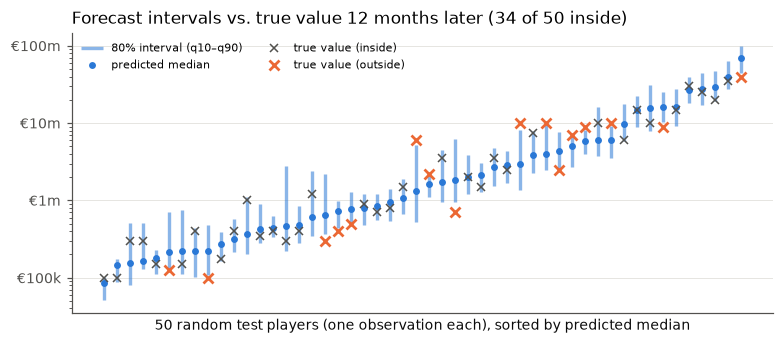

In [13]:
rng = np.random.default_rng(SEED)
one_per_player = te.reset_index().groupby("player_id").sample(1, random_state=SEED)["index"].to_numpy()
pick = np.sort(rng.choice(one_per_player, size=50, replace=False))
v = te["value_t"].to_numpy(float)[pick]
lo, mid, hi = (v * np.exp(Qs[pick, i]) for i in range(3))
true = te["value_target"].to_numpy(float)[pick]
order = np.argsort(mid)
x = np.arange(50)
inside = (true >= lo) & (true <= hi)
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.vlines(x, lo[order], hi[order], color=PALETTE[0], linewidth=2.2, alpha=0.55, label="80% interval (q10–q90)")
ax.plot(x, mid[order], "o", color=PALETTE[0], markersize=3.5, label="predicted median")
ax.plot(x[inside[order]], true[order][inside[order]], "x", color=TEXT_SECONDARY, markersize=5, label="true value (inside)")
ax.plot(x[~inside[order]], true[order][~inside[order]], "x", color=PALETTE[1], markersize=6, mew=1.8,
        label="true value (outside)")
ax.set_yscale("log")
ax.set_yticks([1e5, 1e6, 1e7, 1e8], ["€100k", "€1m", "€10m", "€100m"])
ax.set_xticks([])
ax.set_xlabel("50 random test players (one observation each), sorted by predicted median")
ax.set_title(f"Forecast intervals vs. true value 12 months later ({inside.sum()} of 50 inside)", loc="left")
ax.legend(loc="upper left", fontsize=7, ncols=2)
ax.grid(axis="x", visible=False)
fig.tight_layout()
savefig(fig, "fig15_forecast_intervals")
plt.show()

## C2. Conformal calibration of the 80% interval (no look-ahead)

The raw intervals cover 77.6% instead of 80%. We correct them with **conformalized quantile regression** (CQR), using a calibration set that cannot see the test period.

**Calibration set.** These are the training observations whose **target falls between July 2023 and June 2024**:
- they are excluded from the tuning rows (the embargo), so a model fitted on the tuning rows has never seen them;
- all their targets are dated **before** the test period starts (July 2024);
- the 2023/24 validation year (targets mid-2024 to mid-2025) is **not** used.

**Method:**
1. Fit the 10/50/90% quantile models on the **tuning rows** only (same settings and number of trees as in C).
2. On the calibration set, compute each observation's conformity score $E = \max(\hat q_{10} - y,\; y - \hat q_{90})$, i.e. how far the true change lies outside the interval (negative if inside).
3. Let $Q$ be the $\lceil (1-0.2)(n+1) \rceil$-th smallest score. The calibrated interval is $[\hat q_{10} - Q,\; \hat q_{90} + Q]$.
4. **By-age variant:** the same, but $Q$ is computed separately within each age group (a "Mondrian" calibration). This targets 80% coverage per age group rather than only overall.

**Reported intervals:**
- **A:** the final model of section C (fitted on all training rows), uncalibrated.
- **B:** the tuning-row model, uncalibrated.
- **C:** B calibrated overall.
- **D:** B calibrated by age group.

B to C/D is the formally valid comparison, because the calibration rows are unseen by the model being calibrated.

In [14]:
import lightgbm as lgb
from src.robustness import change
cal = mf["train"][mf["train"]["target_date"] >= TRAIN_END].reset_index(drop=True)      # embargoed rows
assert cal["target_date"].max() < pd.Timestamp(VAL_END) and not cal.index.isin([]).any()
assert len(set(zip(cal.player_id, cal.t)) & set(zip(mf["tune"].player_id, mf["tune"].t))) == 0
print(f"calibration rows: {len(cal):,} (targets {cal.target_date.min().date()} – {cal.target_date.max().date()}), "
      f"players: {cal.player_id.nunique():,}")

base = dict(random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)
Qt_cal, Qt_test = {}, {}
for a in QS:
    m_tune = lgb.LGBMRegressor(n_estimators=trees[a], **base, **(base_params | {"objective": "quantile", "alpha": a}))
    m_tune.fit(mf["tune"][FEATURES], change(mf["tune"]))
    Qt_cal[a], Qt_test[a] = m_tune.predict(cal[FEATURES]), m_tune.predict(te[FEATURES])
Pc = np.sort(np.column_stack([Qt_cal[a] for a in QS]), axis=1)
Pt = np.sort(np.column_stack([Qt_test[a] for a in QS]), axis=1)
y_cal = change(cal).to_numpy()

def cqr_q(scores, alpha=0.2):
    n = len(scores)
    k = int(np.ceil((1 - alpha) * (n + 1)))
    return np.sort(scores)[min(k, n) - 1]

score = np.maximum(Pc[:, 0] - y_cal, y_cal - Pc[:, 2])
Q_all = cqr_q(score)
print(f"raw coverage on the calibration set: {100 * np.mean(score <= 0):.1f}% | overall correction Q = {Q_all:+.4f} log units")

age_cal = pd.cut(cal["age"], AGE_BINS, labels=AGE_LABELS, right=False).astype(str).to_numpy()
age_te = pd.cut(te["age"], AGE_BINS, labels=AGE_LABELS, right=False).astype(str).to_numpy()
Q_age = {g: cqr_q(score[age_cal == g]) for g in AGE_LABELS}
print("correction by age group:", {g: round(q, 4) for g, q in Q_age.items()},
      "| calibration rows per group:", {g: int((age_cal == g).sum()) for g in AGE_LABELS})

def widen(P, q):
    out = P.copy()
    out[:, 0] -= q
    out[:, 2] += q
    return out

P_cal_all = widen(Pt, Q_all)
P_cal_age = widen(Pt, np.array([Q_age[g] for g in age_te]))
variants = {"A: final model, uncalibrated (section C)": Qs, "B: tuning-row model, uncalibrated": Pt,
            "C: B + conformal calibration (overall)": P_cal_all, "D: B + conformal calibration (by age group)": P_cal_age}

calibration rows: 12,799 (targets 2023-07-01 – 2024-06-30), players: 6,451


raw coverage on the calibration set: 77.3% | overall correction Q = +0.0334 log units
correction by age group: {'<21': 0.0671, '21–25': 0.0659, '26–29': 0.0163, '30+': 0.001} | calibration rows per group: {'<21': 1913, '21–25': 5044, '26–29': 3370, '30+': 2470}


In [15]:
rows = []
for name, P in variants.items():
    st = interval_stats(P, te, y)
    rows.append({"interval": name, "group": "all", "rows": len(te),
                 "coverage %": st["coverage of 80% interval %"], "coverage 95% CI": coverage_ci(P, te, y),
                 "below q10 %": st["below q10 %"], "above q90 %": st["above q90 %"],
                 "median width (log)": st["median width (log)"], "mean width (log)": st["mean width (log)"],
                 "median width / value at t (%)": st["median width / value at t (%)"],
                 "median width (EUR m)": st["median width (EUR m)"],
                 "pinball q10": st["pinball q10"], "pinball q90": st["pinball q90"], "mean pinball": st["mean pinball"]})
    for g in AGE_LABELS:
        m = age_te == g
        st = interval_stats(P[m], te[m], y[m])
        rows.append({"interval": name, "group": f"age {g}", "rows": int(m.sum()),
                     "coverage %": st["coverage of 80% interval %"], "coverage 95% CI": coverage_ci(P[m], te[m], y[m]),
                     "below q10 %": st["below q10 %"], "above q90 %": st["above q90 %"],
                     "median width (log)": st["median width (log)"], "mean width (log)": st["mean width (log)"],
                     "median width / value at t (%)": st["median width / value at t (%)"],
                     "median width (EUR m)": st["median width (EUR m)"],
                     "pinball q10": st["pinball q10"], "pinball q90": st["pinball q90"], "mean pinball": st["mean pinball"]})
calib = pd.DataFrame(rows).round(3)
calib.to_csv(RESULTS / "table33_conformal_calibration.csv", index=False)
calib.set_index(["group", "interval"]).sort_index(level=0, sort_remaining=False)

rows  coverage % coverage 95% CI  below q10 %  above q90 %  median width (log)  mean width (log)  \
group     interval                                                                                                                                         
age 21–25 A: final model, uncalibrated (section C)      5038      76.141    [74.7, 77.5]       10.480       13.378               1.191             1.215   
          B: tuning-row model, uncalibrated             5038      75.169    [73.7, 76.6]       10.977       13.855               1.165             1.193   
          C: B + conformal calibration (overall)        5038      77.868    [76.5, 79.2]        9.528       12.604               1.231             1.260   
          D: B + conformal calibration (by age group)   5038      79.933    [78.6, 81.3]        8.356       11.711               1.296             1.325   
age 26–29 A: final model, uncalibrated (section C)      3174      78.607    [77.0, 80.2]       12.350        9.042               0.957             0.969   
          B: tuning-row model, uncalibrated             3174      78.607    [76.9, 80.2]       12.697        8.696               0.952             0.970   
          C: B + conformal calibration (overall)        3174      81.191    [79.7, 82.7]       11.185        7.624               1.019             1.036   
          D: B + conformal calibration (by age group)   3174      80.025    [78.3, 81.6]       11.909        8.066               0.984             1.002   
age 30+   A: final model, uncalibrated (section C)      2269      81.357    [79.4, 83.2]       13.883        4.760               0.841             0.853   
          B: tuning-row model, uncalibrated             2269      81.710    [79.9, 83.5]       14.852        3.438               0.863             0.873   
          C: B + conformal calibration (overall)        2269      84.354    [82.5, 86.0]       13.045        2.600               0.930             0.939   
          D: B + conformal calibration (by age group)   2269      81.798    [79.9, 83.5]       14.764        3.438               0.865             0.875   
age <21   A: final model, uncalibrated (section C)      1686      74.792    [72.3, 77.1]        9.549       15.658               1.682             1.756   
          B: tuning-row model, uncalibrated             1686      73.903    [71.4, 76.2]        9.846       16.251               1.671             1.727   
          C: B + conformal calibration (overall)        1686      76.453    [74.1, 78.7]        8.482       15.065               1.737             1.794   
          D: B + conformal calibration (by age group)   1686      77.639    [75.2, 79.8]        8.066       14.294               1.805             1.861   
all       A: final model, uncalibrated (section C)     12167      77.570    [76.8, 78.5]       11.474       10.956               1.056             1.159   
          B: tuning-row model, uncalibrated            12167      77.110    [76.3, 78.0]       11.991       10.898               1.054             1.149   
          C: B + conformal calibration (overall)       12167      79.749    [78.9, 80.6]       10.471        9.781               1.120             1.216   
          D: B + conformal calibration (by age group)  12167      79.987    [79.2, 80.9]       10.438        9.575               1.130             1.231   

                                                       median width / value at t (%)  median width (EUR m)  pinball q10  pinball q90  mean pinball  
group     interval                                                                                                                                  
age 21–25 A: final model, uncalibrated (section C)                           138.334                 4.085        0.082        0.110         0.134  
          B: tuning-row model, uncalibrated                                  134.356                 3.922        0.082        0.111         0.134  
          C: B + conformal 

# D. Checks on weak spots

## D1. The 17 new leagues: how complete are their performance features?

Match data for these leagues start only in 2024/25. So a new-league test observation's 365-day window is often only partly covered by match data, and the previous-year window (365–730 days before *t*) is not covered at all. We measure:
- how much of each window lies inside the league's match coverage;
- the share of zero or missing performance features, compared with core-league test observations.

In [16]:
from src.features import FEATURE_INFO, CATEGORICAL
from src.robustness import fit_lgb, predict_log, group_features
ds = load_dataset()
_, extra = main_and_extra(ds)
newl = extra[extra.league_group == "new_leagues"].reset_index(drop=True)
core_te = mf["test"]
first_match = cov.set_index("competition_id")["first_match"].pipe(pd.to_datetime)
PERF = group_features("performance")

def window_cov(frame):
    fm = frame["league_t"].astype(str).map(first_match)
    w = ((frame["t"] - fm).dt.days / 365).clip(0, 1)
    return w

comp = pd.DataFrame({
    "rows": [len(core_te), len(newl)],
    "365-day window covered by match data (mean %)": [100 * window_cov(core_te).mean(), 100 * window_cov(newl).mean()],
    "window fully covered (%)": [100 * (window_cov(core_te) >= 1).mean(), 100 * (window_cov(newl) >= 1).mean()],
    "minutes_365 = 0 (%)": [100 * (core_te.minutes_365 == 0).mean(), 100 * (newl.minutes_365 == 0).mean()],
    "minutes_prev_365 = 0 (%)": [100 * (core_te.minutes_prev_365 == 0).mean(), 100 * (newl.minutes_prev_365 == 0).mean()],
    "no appearance on record (%)": [100 * core_te.days_since_last_appearance.isna().mean(),
                                    100 * newl.days_since_last_appearance.isna().mean()],
    "median minutes_365": [core_te.minutes_365.median(), newl.minutes_365.median()],
}, index=["core leagues (test)", "17 new leagues (test)"]).round(1)
zero_share = pd.DataFrame({
    "core leagues (test)": [(core_te[f].fillna(0) == 0).mean() * 100 for f in PERF],
    "17 new leagues (test)": [(newl[f].fillna(0) == 0).mean() * 100 for f in PERF]}, index=PERF).round(1)
comp.to_csv(RESULTS / "table34_new_league_feature_coverage.csv")
zero_share.to_csv(RESULTS / "table34b_new_league_zero_share_by_feature.csv")
display(comp.T)
zero_share

,core leagues (test),17 new leagues (test)
rows,12167.0,8671.0
365-day window covered by match data (mean %),100.0,46.5
window fully covered (%),100.0,0.0
minutes_365 = 0 (%),4.7,87.3
minutes_prev_365 = 0 (%),27.9,91.8
no appearance on record (%),2.9,72.0
median minutes_365,1338.0,0.0


,core leagues (test),17 new leagues (test)
matches_365,4.7,87.3
minutes_365,4.7,87.3
goals_365,45.6,95.9
assists_365,44.7,96.2
ga_per90_365,32.3,94.2
yellow_365,23.4,93.4
red_365,93.2,99.7
league_matches_365,6.2,96.7
league_minutes_365,6.2,96.7
league_ga_per90_365,35.7,98.3


### D1b. New-league test with and without performance features

LightGBM is retrained on the core-league training rows **without** the performance features (tuned settings; same protocol). We then score both versions on the 17-new-league test observations against the naive forecast and the age × value curve, using paired player-level bootstrap intervals.

In [17]:
best = json.load(open(RESULTS / "best_params.json"))["LightGBM"]
LGB_TUNED = {k: v for k, v in best.items() if k != "n_trees"} | {"learning_rate": 0.03, "subsample_freq": 1}
no_perf = [f for f in FEATURES if f not in PERF]
m_noperf, n_noperf = fit_lgb(LGB_TUNED, no_perf, mf["tune"], mf["val"], mf["train"])
saved = pd.read_parquet(ROOT / "data" / "processed" / "predictions_test.parquet")
sv = saved[saved.test_set == "new_leagues"][["player_id", "t", "pred_LightGBM", "pred_Age-value_curve", "pred_Naive"]]
nl = newl.merge(sv, on=["player_id", "t"], how="left", validate="one_to_one")
assert nl["pred_LightGBM"].notna().all()
nl["pred_LightGBM_noperf"] = predict_log(m_noperf, no_perf, nl)
core_nl = core_te.copy()
core_nl["pred_LightGBM_noperf"] = predict_log(m_noperf, no_perf, core_te)
core_saved = saved[saved.test_set == "core"][["player_id", "t", "pred_LightGBM", "pred_Age-value_curve", "pred_Naive"]]
core_nl = core_nl.merge(core_saved, on=["player_id", "t"], validate="one_to_one")

def compare(frame, label, seed_offset=0):
    cols = {"no change": "pred_Naive", "age × value curve": "pred_Age-value_curve",
            "LightGBM (all 50 features)": "pred_LightGBM", "LightGBM without performance": "pred_LightGBM_noperf"}
    err = pd.DataFrame({k: (frame[c] - frame.y).abs() for k, c in cols.items()})
    b = cluster_bootstrap_means(frame.player_id, err, seed=SEED + seed_offset)
    j = {k: i for i, k in enumerate(cols)}
    out = []
    for k in ["LightGBM (all 50 features)", "LightGBM without performance", "age × value curve"]:
        row = {"test set": label, "model": k, "MAE": err[k].mean(),
               "skill vs no change %": 100 * (1 - err[k].mean() / err["no change"].mean()),
               "  CI": "[{:.1f}, {:.1f}]".format(*ci(100 * (1 - b[:, j[k]] / b[:, j["no change"]])))}
        if k != "age × value curve":
            row |= {"skill vs curve %": 100 * (1 - err[k].mean() / err["age × value curve"].mean()),
                    "  CI ": "[{:.1f}, {:.1f}]".format(*ci(100 * (1 - b[:, j[k]] / b[:, j["age × value curve"]])))}
        out.append(row)
    d = b[:, j["LightGBM without performance"]] - b[:, j["LightGBM (all 50 features)"]]
    out.append({"test set": label, "model": "difference: without − with performance (MAE)",
                "MAE": err["LightGBM without performance"].mean() - err["LightGBM (all 50 features)"].mean(),
                "  CI": "[{:.4f}, {:.4f}]".format(*ci(d))})
    return out

nl_res = pd.DataFrame(compare(nl, "17 new leagues") + compare(core_nl, "14 core leagues", 1)).round(4)
nl_res.to_csv(RESULTS / "table35_new_leagues_without_performance.csv", index=False)
print(f"trees without performance features: {n_noperf}")
nl_res.set_index(["test set", "model"])

trees without performance features: 347


MAE  skill vs no change %                CI  skill vs curve %         CI 
test set        model                                                                                                                     
17 new leagues  LightGBM (all 50 features)                    0.3880               13.3219      [12.2, 14.5]            4.1014  [3.1, 5.1]
                LightGBM without performance                  0.3961               11.5139      [10.2, 12.9]            2.1011  [0.9, 3.2]
                age × value curve                             0.4046                9.6149       [8.3, 11.0]               NaN         NaN
                difference: without − with performance (MAE)  0.0081                   NaN  [0.0052, 0.0109]               NaN         NaN
14 core leagues LightGBM (all 50 features)                    0.3940               17.9166      [16.8, 19.0]            6.7725  [5.9, 7.6]
                LightGBM without performance                  0.4004               16.5794      [15.5, 17.6]            5.2538  [4.4, 6.0]
                age × value curve                             0.4226               11.9537      [10.9, 13.0]               NaN         NaN
                difference: without − with performance (MAE)  0.0064                   NaN  [0.0050, 0.0076]               NaN         NaN

## D2. Snapshot features: LightGBM without position, sub-position, height and foot

These attributes come from the 2026 snapshot of the players table. Height and foot rarely change, but position can change over a career. We retrain LightGBM without them (tuned settings, same protocol) and compare with the full model on the core test set (paired player-level bootstrap).

In [18]:
SNAP = ["position", "sub_position", "height_cm", "foot"]
no_snap = [f for f in FEATURES if f not in SNAP]
m_full, n_full = fit_lgb(LGB_TUNED, FEATURES, mf["tune"], mf["val"], mf["train"])
m_ns, n_ns = fit_lgb(LGB_TUNED, no_snap, mf["tune"], mf["val"], mf["train"])
p_full, p_ns = predict_log(m_full, FEATURES, core_te), predict_log(m_ns, no_snap, core_te)
curve_te = core_nl.set_index(["player_id", "t"]).loc[list(zip(core_te.player_id, core_te.t)), "pred_Age-value_curve"].to_numpy()
err = pd.DataFrame({"full": np.abs(p_full - core_te.y), "no_snap": np.abs(p_ns - core_te.y),
                    "naive": np.abs(core_te.log_value - core_te.y), "curve": np.abs(curve_te - core_te.y)})
b = cluster_bootstrap_means(core_te.player_id, err)
snap = pd.DataFrame({
    "model": ["LightGBM, all 50 features", "LightGBM without position/sub-position/height/foot"],
    "features": [len(FEATURES), len(no_snap)], "trees": [n_full, n_ns],
    "MAE": [err.full.mean(), err.no_snap.mean()],
    "skill vs no change %": [100 * (1 - err.full.mean() / err.naive.mean()), 100 * (1 - err.no_snap.mean() / err.naive.mean())],
    "skill vs curve %": [100 * (1 - err.full.mean() / err.curve.mean()), 100 * (1 - err.no_snap.mean() / err.curve.mean())],
    "skill vs curve 95% CI": ["[{:.1f}, {:.1f}]".format(*ci(100 * (1 - b[:, 0] / b[:, 3]))),
                              "[{:.1f}, {:.1f}]".format(*ci(100 * (1 - b[:, 1] / b[:, 3])))]}).set_index("model")
lo, hi = ci(b[:, 1] - b[:, 0])
snap.loc["difference (without − with)", ["MAE"]] = [err.no_snap.mean() - err.full.mean()]
snap.loc["difference (without − with)", "skill vs curve 95% CI"] = f"MAE diff CI [{lo:.4f}, {hi:.4f}]"
snap = snap.round(4)
snap.to_csv(RESULTS / "table36_without_snapshot_features.csv")
assert abs(err.full.mean() - 0.3940) < 5e-4      # same as the main LightGBM
snap

,features,trees,MAE,skill vs no change %,skill vs curve %,skill vs curve 95% CI
model,,,,,,
"LightGBM, all 50 features",50.0,596.0,0.3940,17.9166,6.7725,"[6.0, 7.6]"
LightGBM without position/sub-position/height/foot,46.0,624.0,0.3951,17.6911,6.5164,"[5.7, 7.4]"
difference (without − with),NaN,NaN,0.0011,NaN,NaN,"MAE diff CI [0.0000, 0.0021]"


## D3. Real-fee check: does the forecast relate to actual transfer fees?

The target is Transfermarkt's own estimate. Here we check whether the forecasts also say something about **real money**.
- **Sample:** core test observations whose player was sold for a fee within 12 months after *t* (first paid transfer in $(t, t+365]$).
- **Outcome:** $\log(\text{fee} / \text{market value at } t)$.
- **Measure:** Spearman correlation of the outcome with the predicted change (LightGBM and the age × value curve), with player-level bootstrap intervals.
- **References:**
  - the *true* 12-month change of the Transfermarkt value, which is an upper reference for what forecasting the value could achieve here;
  - minus age (younger = higher).

In [19]:
from scipy.stats import spearmanr
tr_ = d["transfers"]
paid = tr_[(tr_.transfer_fee > 0) & (tr_.transfer_date <= pd.Timestamp("2026-10-17"))][["player_id", "transfer_date", "transfer_fee"]]
cs = core_saved.merge(core_te[["player_id", "t", "y", "log_value", "value_t", "age"]], on=["player_id", "t"])
mm = cs.reset_index().merge(paid, on="player_id")
mm = mm[(mm.transfer_date > mm.t) & (mm.transfer_date <= mm.t + 365 * DAY)]
mm = mm.sort_values("transfer_date").drop_duplicates("index")
mm["fee_ratio"] = np.log(mm.transfer_fee.astype(float) / mm.value_t.astype(float))
preds_fee = {"LightGBM predicted change": mm.pred_LightGBM - mm.log_value,
             "age × value curve predicted change": mm["pred_Age-value_curve"] - mm.log_value,
             "true 12-month change of the market value (reference)": mm.y - mm.log_value,
             "minus age (reference)": -mm.age}
rng = np.random.default_rng(SEED)
players = mm.player_id.unique()
rows_by_player = {p: np.flatnonzero(mm.player_id.to_numpy() == p) for p in players}
draws = []
for _ in range(1000):
    pick = rng.choice(players, size=len(players), replace=True)
    idx = np.concatenate([rows_by_player[p] for p in pick])
    draws.append({k: spearmanr(v.to_numpy()[idx], mm.fee_ratio.to_numpy()[idx]).statistic for k, v in preds_fee.items()})
draws = pd.DataFrame(draws)
fee = pd.DataFrame({"Spearman rho with log(fee / value at t)": {k: spearmanr(v, mm.fee_ratio).statistic for k, v in preds_fee.items()},
                    "95% CI": {k: "[{:.2f}, {:.2f}]".format(*ci(draws[k])) for k in preds_fee}})
d_ = draws["LightGBM predicted change"] - draws["age × value curve predicted change"]
fee.loc["difference LightGBM − curve", :] = [fee.iloc[0, 0] - fee.iloc[1, 0], "[{:.2f}, {:.2f}]".format(*ci(d_))]
d_age = draws["LightGBM predicted change"] - draws["minus age (reference)"]
fee.loc["difference LightGBM − minus age", :] = [fee.iloc[0, 0] - fee.iloc[3, 0], "[{:.2f}, {:.2f}]".format(*ci(d_age))]
fee = fee.round(3)
fee.to_csv(RESULTS / "table37_real_fee_check.csv")
print(f"sold-for-a-fee observations: {len(mm):,} ({mm.player_id.nunique():,} players); "
      f"median fee / value at t = {np.exp(mm.fee_ratio.median()):.2f}")
fee

sold-for-a-fee observations: 2,100 (1,121 players); median fee / value at t = 0.88


,Spearman rho with log(fee / value at t),95% CI
LightGBM predicted change,0.403,"[0.35, 0.46]"
age × value curve predicted change,0.330,"[0.28, 0.39]"
true 12-month change of the market value (reference),0.572,"[0.53, 0.62]"
minus age (reference),0.377,"[0.32, 0.43]"
difference LightGBM − curve,0.073,"[0.03, 0.11]"
difference LightGBM − minus age,0.027,"[-0.01, 0.07]"


## D4. Euro metrics: MdAPE first, "within ±20%" second

From here on, the paper uses the **median absolute percentage error (MdAPE)** as the main euro metric. The share within ±20% stays as a secondary metric, with its tie rule: errors of exactly 20% count as within, because Transfermarkt's rounded values create many exact ties. Both are already in every result table, so no new computation is needed; the paper tables are updated in Step F.